In [4]:
import pandas as pd
parquet_path = "civictech_unified.parquet"
df=pd.read_parquet(parquet_path)
df.head()

,id,ctfg_slug,name,alt_names,description,description_de,url,url_flag,repository_url,status,...,start_year,end_year,impact,notes,language,sources,n_sources,source_ids,source_urls,raw_fields
0,botometer-blue,botometer-blue,Botometer Blue,[Botometer],Botometer first collects data from the social ...,Botometer sammelt zunächst Daten von der Socia...,https://botometer.osome.iu.edu/,ok,NaN,active,...,2026,<NA>,NaN,NaN,English,"[CTFG, HIIG, CivicDataLab]",3,"[botometer-blue, hiig:Botometer, cdl:124]",[https://directory.civictech.guide/listing/Bot...,"{""botometer-blue"": {""Type"": [""Tool or platform..."
1,climate-trace,climate-trace,Climate TRACE,[],Climate TRACE is a non-profit coalition of org...,Climate TRACE ist eine gemeinnützige Koalition...,https://climatetrace.org/,ok,NaN,active,...,<NA>,<NA>,NaN,NaN,English,"[CTFG, HIIG, CivicDataLab]",3,"[climate-trace, hiig:Climate TRACE, cdl:167]",[https://directory.civictech.guide/listing/Cli...,"{""climate-trace"": {""SDGs"": [""recgbaJPtSQGdthSI..."
2,datakind,datakind,DataKind,[DataKind: efficient vaccine coverage],DataKind is an organisation that brings pro bo...,"DataKind ist eine Organisation, die ehrenamtli...",http://www.datakind.org/,ok,NaN,active,...,2011,<NA>,has completed over 250 projects by deploying e...,NaN,English,"[CTFG, HIIG, CivicDataLab]",3,"[datakind, hiig:DataKind: efficient vaccine co...",[https://directory.civictech.guide/listing/Dat...,"{""datakind"": {""Jobs"": [""recTHibx4XPHk9mnD""], ""..."
3,full-fact,full-fact,Full Fact,[],Full fact is a non-profit initiative that uses...,"Full Fact ist eine gemeinnützige Initiative, d...",https://fullfact.org/,ok,NaN,active,...,2009,<NA>,NaN,NaN,English,"[CTFG, HIIG, CivicDataLab]",3,"[full-fact, hiig:Full Fact, cdl:362]",[https://directory.civictech.guide/listing/Ful...,"{""full-fact"": {""Jobs"": [], ""Type"": [""Publicati..."
4,masakhane,masakhane,Masakhane,[MasakhaNER],Masakhane is a grassroots organisation whose m...,Eigennamenerkennung (Named Entity Recognition)...,https://www.masakhane.io/,ok,NaN,active,...,<NA>,<NA>,NaN,NaN,English,"[CTFG, HIIG, CivicDataLab]",3,"[masakhane, hiig:MasakhaNER, cdl:642]",[https://directory.civictech.guide/listing/Mas...,"{""masakhane"": {""Tags"": ""decolonization"", ""Type..."


In [5]:
df.columns

Index(['id', 'ctfg_slug', 'name', 'alt_names', 'description', 'description_de',
       'url', 'url_flag', 'repository_url', 'status', 'status_raw', 'org_type',
       'organization', 'city', 'country', 'countries', 'region',
       'geographic_focus', 'sdgs', 'categories', 'issues', 'tags',
       'technologies', 'ai_technology', 'ai_related', 'project_type',
       'funding', 'open_source', 'open_source_license', 'start_year',
       'end_year', 'impact', 'notes', 'language', 'sources', 'n_sources',
       'source_ids', 'source_urls', 'raw_fields'],
      dtype='str')

In [6]:
print('Rows and columns', df.shape)

Rows and columns (14491, 39)


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
useful_cols = [
    "id",
    "name",
    "status",
    "countries",
    "geographic_focus",
    "language",
    "issues",
    "sdgs",
    "sources",
]
df_sub = df[useful_cols].copy()

print(f"Dataset loaded: {df_sub.shape[0]} projects.")

Dataset loaded: 14491 projects.


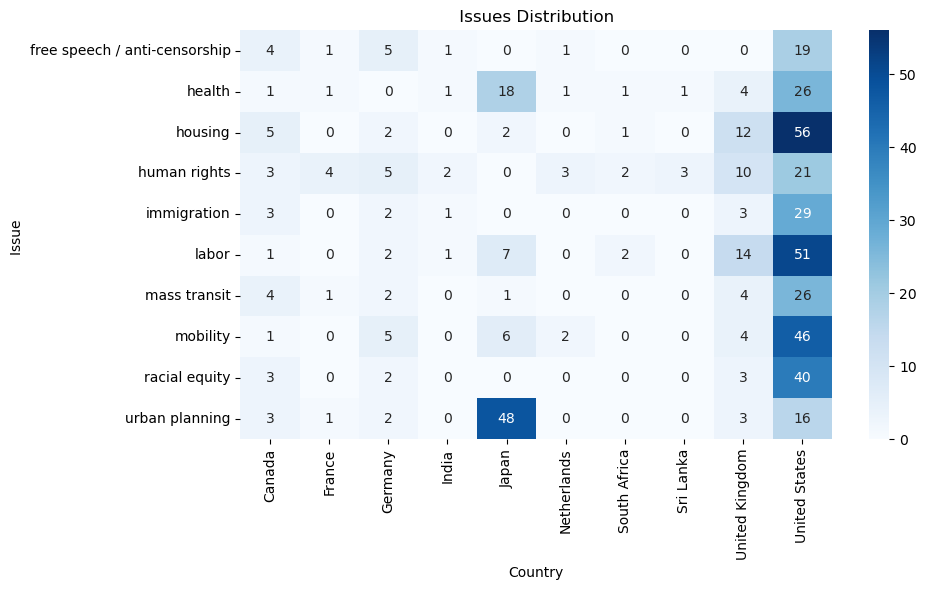

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
df_cross = pd.read_parquet(
    parquet_path, columns=["issues", "countries"]
)

df_cross = (
    df_cross.explode("issues")
    .explode("countries")
    .dropna(subset=["issues", "countries"])
    .reset_index(drop=True)
)

df_cross = df_cross[
    (df_cross["issues"].astype(str).str.strip() != "")
    & (df_cross["countries"].astype(str).str.strip() != "")
]

top_issues = df_cross["issues"].value_counts().head(10).index
top_countries = df_cross["countries"].value_counts().head(10).index

filtered_df = df_cross[
    df_cross["issues"].isin(top_issues)
    & df_cross["countries"].isin(top_countries)
].copy()

ct = pd.crosstab(filtered_df["issues"], filtered_df["countries"])

plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title(" Issues Distribution ")
plt.xlabel("Country")
plt.ylabel("Issue ")
plt.tight_layout()
plt.savefig("issues_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
import pandas as pd

# 1. Load key columns for data completeness check
target_cols = [
    "id",
    "sources",
    "issues",
    "countries",
    "geographic_focus",
    "language",
    "status",
]
df_missing = pd.read_parquet("civictech_unified.parquet", columns=target_cols)

# 2. Overall missing value percentage per key column
cols_to_eval = ["issues", "countries", "geographic_focus", "language", "status"]
summary_df = pd.DataFrame({
    "missing_count": df_missing[cols_to_eval].isna().sum(),
    "missing_percentage": (
        df_missing[cols_to_eval].isna().mean() * 100
    ).round(2),
}).sort_values("missing_percentage", ascending=False)

print("=== 1. MISSING VALUES IN KEY FIELDS ===")
print(summary_df)
print("\n" + "=" * 50 + "\n")

# 3. Analyze missing country data per contributing source
df_src_geo = (
    df_missing[["sources", "countries"]]
    .explode("sources")
    .reset_index(drop=True)
)

df_src_geo["country_missing"] = df_src_geo["countries"].isna()

missing_by_source = (
    df_src_geo.groupby("sources")["country_missing"]
    .agg(total_projects="count", missing_countries="sum", missing_pct="mean")
    .reset_index()
)

missing_by_source["missing_pct"] = (
    missing_by_source["missing_pct"] * 100
).round(2)
missing_by_source = missing_by_source.sort_values(
    "missing_pct", ascending=False
)

print("=== 2. MISSING COUNTRY DATA BY SOURCE ===")
print(missing_by_source.to_string(index=False))
print(missing_by_source.to_markdown(index=False))

=== 1. MISSING VALUES IN KEY FIELDS ===
                  missing_count  missing_percentage
language                    490                3.38
issues                        0                0.00
countries                     0                0.00
geographic_focus              0                0.00
status                        0                0.00


=== 2. MISSING COUNTRY DATA BY SOURCE ===
            sources  total_projects  missing_countries  missing_pct
 Awesome-Civic-Tech              34                  0          0.0
               CTFG           13329                  0          0.0
       CivicDataLab            1068                  0          0.0
CivicTechFundAfrica              36                  0          0.0
          CodeForDE             248                  0          0.0
               HIIG             209                  0          0.0
     HackCorruption               4                  0          0.0
| sources             |   total_projects |   missing_countri

<Figure size 1100x600 with 0 Axes>

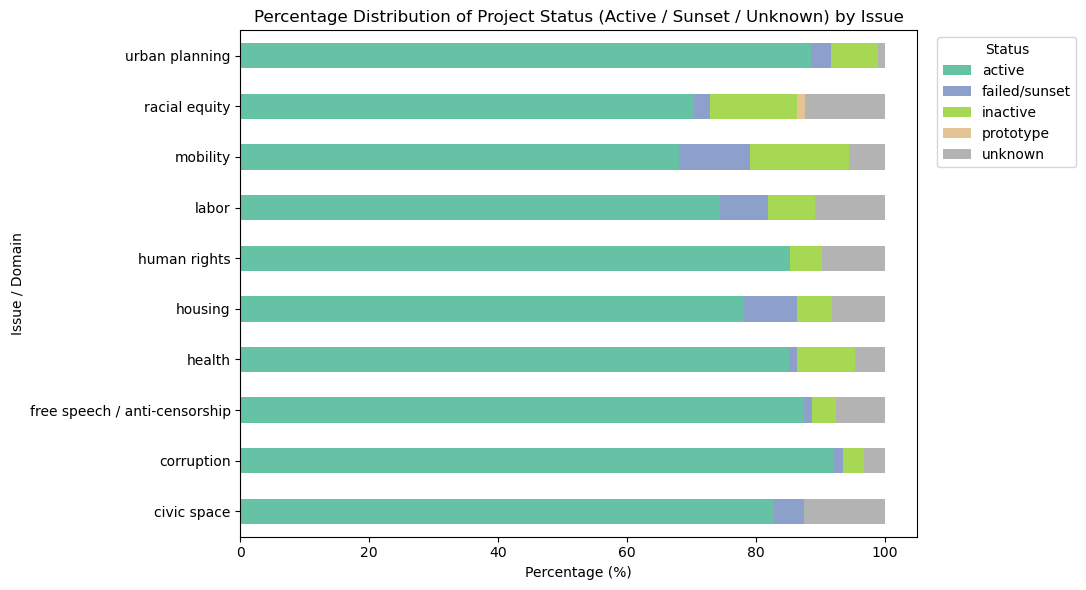

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load data
df_status = pd.read_parquet(
    "civictech_unified.parquet", columns=["issues", "status"]
)

# 2. Explode issues and reset index
df_status = (
    df_status.explode("issues")
    .dropna(subset=["issues"])
    .reset_index(drop=True)
)

df_status["issues"] = df_status["issues"].astype(str).str.strip()
df_status = df_status[df_status["issues"] != ""]

# Handle missing status values by labeling them as 'unknown'
df_status["status"] = df_status["status"].fillna("unknown")

# 3. Top 10 issues by frequency
top_issues_status = df_status["issues"].value_counts().head(10).index
filtered_status = df_status[df_status["issues"].isin(top_issues_status)].copy()

# 4. Row-normalized crosstab (percentages)
status_pct = (
    pd.crosstab(
        filtered_status["issues"],
        filtered_status["status"],
        normalize="index",
    )
    * 100
)

# 5. Stacked Horizontal Bar Chart
plt.figure(figsize=(11, 6))
ax = status_pct.plot(
    kind="barh", stacked=True, figsize=(11, 6), colormap="Set2"
)

plt.title(
    "Percentage Distribution of Project Status (Active / Sunset / Unknown)"
    " by Issue",
    fontsize=12,
)
plt.xlabel("Percentage (%)", fontsize=10)
plt.ylabel("Issue / Domain", fontsize=10)
plt.legend(title="Status", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("percentage_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Carichiamo i campi utili per l'analisi dei progetti non attivi
cols = [
    "id",
    "name",
    "status",
    "issues",
    "countries",
    "sources",
    "technologies",
    "start_year",
    "end_year",
    "ai_related",
]
df = pd.read_parquet("civictech_unified.parquet", columns=cols)

# Gestiamo i valori nulli sullo status categorizzandoli come 'unknown'
df["status"] = df["status"].fillna("unknown")

# 2. Filtriamo solo i progetti non attivi
non_active_statuses = ["failed/sunset", "inactive", "unknown"]
df_non_active = df[df["status"].isin(non_active_statuses)].copy()

print(f"Total projects in dataset: {len(df)}")
print(f"Non-active / Unknown projects: {len(df_non_active)}")
print("\nBreakdown of Non-Active Statuses:")
print(df_non_active["status"].value_counts())
print("\n" + "=" * 50 + "\n")

# 3. Analisi per fonte: Quali repository/fonti contengono la maggior parte dei progetti non attivi?
df_src = df_non_active.explode("sources").reset_index(drop=True)
src_status_ct = pd.crosstab(df_src["sources"], df_src["status"])

print("=== NON-ACTIVE PROJECTS BY SOURCE ===")
print(src_status_ct)
print("\n" + "=" * 50 + "\n")

# 4. Distribuzione per anno di avvio (Start Year) dei progetti Sunset/Failed
df_years = df_non_active.dropna(subset=["start_year"]).copy()
df_years["start_year"] = pd.to_numeric(
    df_years["start_year"], errors="coerce"
)


# Explode dei paesi per i soli progetti non attivi (failed/sunset o inactive)
non_active_geo = (
    df_non_active[
        df_non_active["status"].isin(["failed/sunset", "inactive"])
    ]
    .explode("countries")
    .dropna(subset=["countries"])
)

print("=== TOP COUNTRIES WITH FAILED/SUNSET & INACTIVE PROJECTS ===")
print(non_active_geo["countries"].value_counts().head(10))


Total projects in dataset: 14491
Non-active / Unknown projects: 4317

Breakdown of Non-Active Statuses:
status
unknown          1716
inactive         1518
failed/sunset    1083
Name: count, dtype: int64


=== NON-ACTIVE PROJECTS BY SOURCE ===
status               failed/sunset  inactive  unknown
sources                                              
Awesome-Civic-Tech               3         0        9
CTFG                          1072      1362     1304
CivicDataLab                    13       157      349
CivicTechFundAfrica              0         0       35
CodeForDE                        6        90       43
HIIG                             0         3      110


=== TOP COUNTRIES WITH FAILED/SUNSET & INACTIVE PROJECTS ===
countries
United States     705
Germany           220
United Kingdom    146
France             42
Brazil             36
Canada             35
Kenya              30
Romania            24
South Africa       22
Australia          22
Name: count, dtype: int64


=== TOP ISSUES WITH HIGHEST SUNSET / FAILURE RATES (Min. 20 Projects) ===
                                        issues  total_projects  sunset_failed_count  sunset_failure_rate_pct  non_active_rate_pct
                                      COVID-19              21                    3                    14.29                38.10
                                      mobility              91                   10                    10.99                26.37
                                  mass transit              56                    6                    10.71                32.14
                               anti-harassment              29                    3                    10.34                24.14
                                         peace              40                    4                    10.00                17.50
                                          land              24                    2                     8.33                16.67
                

/tmp/ipykernel_9242/1133872979.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


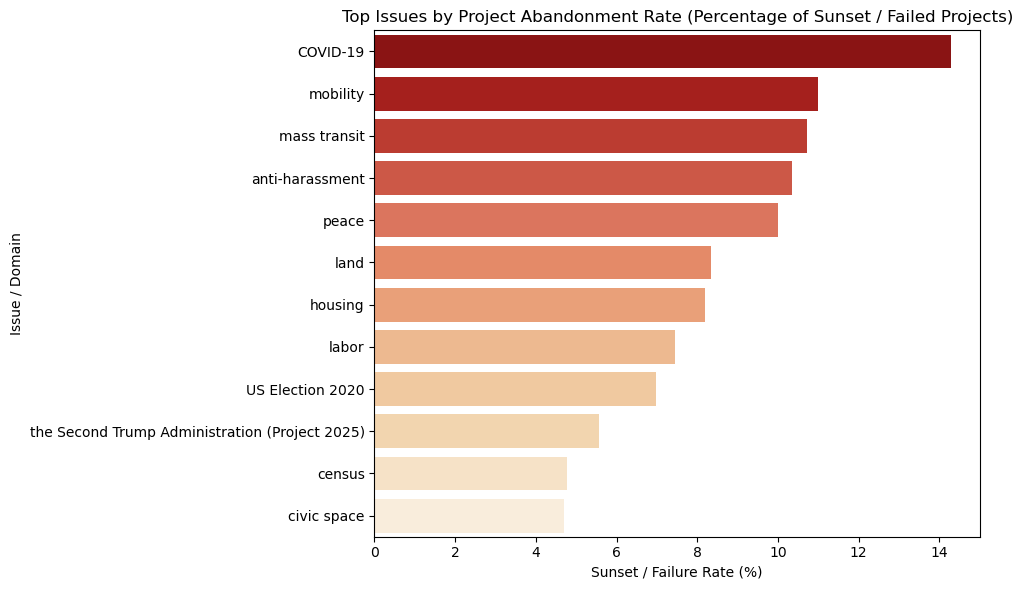

| issues                                         |   total_projects |   sunset_failed_count |   total_non_active_count |   sunset_failure_rate_pct |   non_active_rate_pct |
|:-----------------------------------------------|-----------------:|----------------------:|-------------------------:|--------------------------:|----------------------:|
| COVID-19                                       |               21 |                     3 |                        8 |                     14.29 |                 38.1  |
| mobility                                       |               91 |                    10 |                       24 |                     10.99 |                 26.37 |
| mass transit                                   |               56 |                     6 |                       18 |                     10.71 |                 32.14 |
| anti-harassment                                |               29 |                     3 |                        7 |               

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load parquet dataset with issues and status columns
df_issues_status = pd.read_parquet(
    "civictech_unified.parquet", columns=["issues", "status"]
)

# 2. Explode issues list and reset index
df_issues_status = (
    df_issues_status.explode("issues")
    .dropna(subset=["issues"])
    .reset_index(drop=True)
)

df_issues_status["issues"] = (
    df_issues_status["issues"].astype(str).str.strip()
)
df_issues_status = df_issues_status[df_issues_status["issues"] != ""]

# Fill missing status values as 'unknown'
df_issues_status["status"] = df_issues_status["status"].fillna("unknown")

# 3. Create boolean flags for abandoned/inactive projects
df_issues_status["is_sunset_or_failed"] = df_issues_status["status"] == (
    "failed/sunset"
)
df_issues_status["is_non_active"] = df_issues_status["status"].isin(
    ["failed/sunset", "inactive"]
)

# 4. Group by issue and calculate total projects, sunset count, and percentage
issue_abandonment = (
    df_issues_status.groupby("issues")
    .agg(
        total_projects=("status", "count"),
        sunset_failed_count=("is_sunset_or_failed", "sum"),
        total_non_active_count=("is_non_active", "sum"),
    )
    .reset_index()
)

# Filter out low-sample issues (e.g., issues with fewer than 20 projects) to avoid skewed percentages
issue_abandonment = issue_abandonment[
    issue_abandonment["total_projects"] >= 20
].copy()

issue_abandonment["sunset_failure_rate_pct"] = (
    (
        issue_abandonment["sunset_failed_count"]
        / issue_abandonment["total_projects"]
    )
    * 100
).round(2)
issue_abandonment["non_active_rate_pct"] = (
    (
        issue_abandonment["total_non_active_count"]
        / issue_abandonment["total_projects"]
    )
    * 100
).round(2)

# Sort by highest sunset/failed rate
top_abandoned_issues = issue_abandonment.sort_values(
    "sunset_failure_rate_pct", ascending=False
).head(12)

print("=== TOP ISSUES WITH HIGHEST SUNSET / FAILURE RATES (Min. 20 Projects) ===")
print(
    top_abandoned_issues[
        [
            "issues",
            "total_projects",
            "sunset_failed_count",
            "sunset_failure_rate_pct",
            "non_active_rate_pct",
        ]
    ].to_string(index=False)
)

# 5. Visualizing the Top Abandoned Issues
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_abandoned_issues,
    y="issues",
    x="sunset_failure_rate_pct",
    palette="OrRd_r",
)

plt.title(
    "Top Issues by Project Abandonment Rate (Percentage of Sunset / Failed"
    " Projects)",
    fontsize=12,
)
plt.xlabel("Sunset / Failure Rate (%)", fontsize=10)
plt.ylabel("Issue / Domain", fontsize=10)
plt.tight_layout()
plt.savefig("top_issue_abandonment.png", dpi=300, bbox_inches="tight")
plt.show()
print(top_abandoned_issues.to_markdown(index=False))

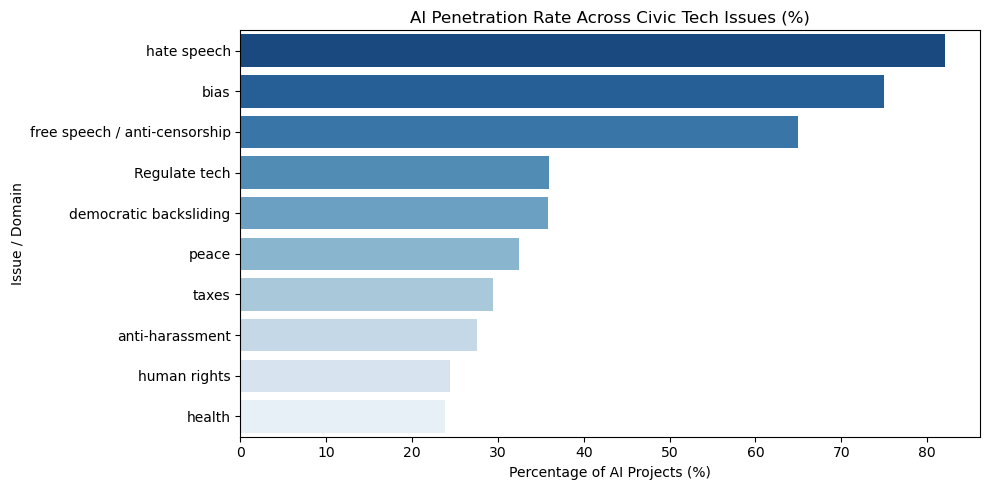

=== 3. MOST FREQUENT AI TECHNOLOGIES / APPROACHES ===
ai_technology
Artificial Intelligence (general)    1526
NLP                                   341
Machine Learning                      286
Generative AI / LLM                   259
Computer Vision                       248
Chatbot / Conversational AI           120
|   count |
|--------:|
|    1526 |
|     341 |
|     286 |
|     259 |
|     248 |
|     120 |


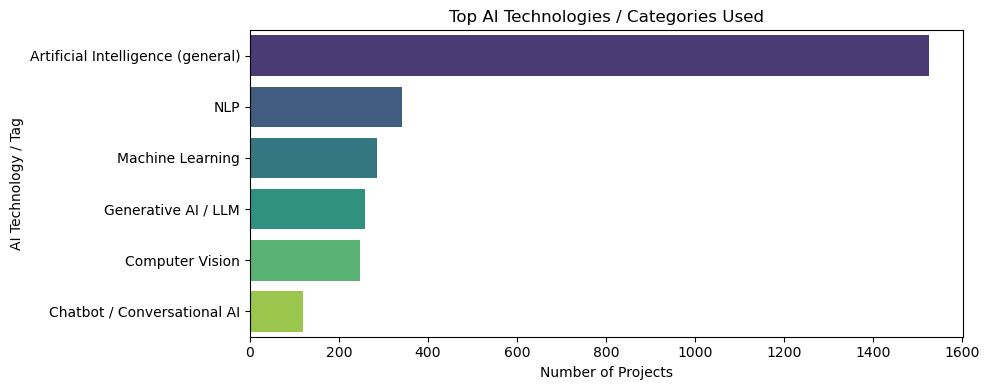

In [18]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

os.makedirs("assets", exist_ok=True)
parquet_path = "civictech_unified.parquet"

# 1. Load data with AI-related fields
cols = [
    "id",
    "name",
    "ai_related",
    "ai_technology",
    "technologies",
    "issues",
    "countries",
    "status",
]
df_ai = pd.read_parquet(parquet_path, columns=cols)
df_ai["ai_related"] = df_ai["ai_related"].fillna(False).astype(bool)

# 2. Compute AI penetration by issue (min. 20 projects)
df_issues_ai = (
    df_ai[["issues", "ai_related"]]
    .explode("issues")
    .dropna(subset=["issues"])
    .reset_index(drop=True)
)
df_issues_ai["issues"] = df_issues_ai["issues"].astype(str).str.strip()
df_issues_ai = df_issues_ai[df_issues_ai["issues"] != ""]

issue_ai_summary = (
    df_issues_ai.groupby("issues")
    .agg(
        total_projects=("ai_related", "count"),
        ai_projects=("ai_related", "sum"),
    )
    .reset_index()
)
issue_ai_summary = issue_ai_summary[
    issue_ai_summary["total_projects"] >= 20
].copy()
issue_ai_summary["ai_penetration_pct"] = (
    (issue_ai_summary["ai_projects"] / issue_ai_summary["total_projects"]) * 100
).round(2)
issue_ai_summary = issue_ai_summary.sort_values(
    "ai_penetration_pct", ascending=False
)

# Plot 1: AI Penetration Rate per Issue
plt.figure(figsize=(10, 5))
sns.barplot(
    data=issue_ai_summary.head(10),
    y="issues",
    x="ai_penetration_pct",
    hue="issues",
    palette="Blues_r",
    legend=False,
)
plt.title("AI Penetration Rate Across Civic Tech Issues (%)", fontsize=12)
plt.xlabel("Percentage of AI Projects (%)", fontsize=10)
plt.ylabel("Issue / Domain", fontsize=10)
plt.tight_layout()
plt.savefig("assets/ai_penetration_issues.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: Top AI Technologies
if "ai_technology" in df_ai.columns and df_ai["ai_technology"].notna().any():
  df_tech = df_ai[df_ai["ai_related"]][["ai_technology"]].copy()
  df_tech = df_tech.explode("ai_technology").dropna().reset_index(drop=True)
  df_tech["ai_technology"] = df_tech["ai_technology"].astype(str).str.strip()

  top_ai_tech = df_tech["ai_technology"].value_counts().head(10)

  print("=== 3. MOST FREQUENT AI TECHNOLOGIES / APPROACHES ===")
  print(top_ai_tech.to_string())
  print(top_ai_tech.to_markdown(index=False))  

  plt.figure(figsize=(10, 4))
  sns.barplot(
      y=top_ai_tech.index,
      x=top_ai_tech.values,
      hue=top_ai_tech.index,
      palette="viridis",
      legend=False,
  )
  plt.title("Top AI Technologies / Categories Used", fontsize=12)
  plt.xlabel("Number of Projects", fontsize=10)
  plt.ylabel("AI Technology / Tag", fontsize=10)
  plt.tight_layout()
  
  plt.savefig("assets/ai_technologies.png", dpi=300, bbox_inches="tight")  
  plt.show()